In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

def generate_random_latin_square(p=4):

    np.random.seed(17)

    # 1. Buat bujur sangkar standar awal
    # Baris pertama: [0, 1, 2, 3] dst dengan pergeseran (shift)
    latin_square = np.array([(np.arange(p) + i) % p for i in range(p)])

    print(latin_square)

    # 2. Randomisasi baris
    row_perm = np.random.permutation(p)
    latin_square = latin_square[row_perm, :]

    print(latin_square) 

    # 3. Randomisasi kolom
    col_perm = np.random.permutation(p)
    latin_square = latin_square[:, col_perm]

    print(latin_square)

    # 4. Petakan angka (0, 1, 2, 3) ke perlakuan (A, B, C, D) secara acak
    treatments = ['A', 'B', 'C', 'D']
    shuffled_treatments = np.random.permutation(treatments)

    print(shuffled_treatments)

    # Buat fungsi untuk memetakan angka ke huruf perlakuan
    vectorized_map = np.vectorize(lambda x: shuffled_treatments[x])


    final_square = vectorized_map(latin_square)

    print(final_square)

    return final_square, row_perm, col_perm



In [6]:
# Lakukan randomisasi
p = 4
latin_matrix, rows, cols = generate_random_latin_square(p)

[[0 1 2 3]
 [1 2 3 0]
 [2 3 0 1]
 [3 0 1 2]]
[[0 1 2 3]
 [2 3 0 1]
 [1 2 3 0]
 [3 0 1 2]]
[[0 1 3 2]
 [2 3 1 0]
 [1 2 0 3]
 [3 0 2 1]]
['C' 'D' 'B' 'A']
[['C' 'D' 'A' 'B']
 ['B' 'A' 'D' 'C']
 ['D' 'B' 'C' 'A']
 ['A' 'C' 'B' 'D']]


In [7]:
# Definisikan nama Baris (misal: Jenis Mobil) dan Kolom (misal: Posisi Roda)
# Sesuai dengan ilustrasi Anda sebelumnya
mobil = ['I', 'II', 'III', 'IV']
posisi = ['Depan Kanan (FR)', 'Depan Kiri (FL)', 'Belakang Kanan (RR)', 'Belakang Kiri (RL)']

In [8]:
# Masukkan ke dalam DataFrame pandas untuk tampilan yang rapi
df_latin = pd.DataFrame(latin_matrix, index=mobil, columns=posisi)
#print("Hasil Randomisasi Rancangan Bujur Sangkar Latin (p = 4):\n")
display(df_latin)

,Depan Kanan (FR),Depan Kiri (FL),Belakang Kanan (RR),Belakang Kiri (RL)
I,C,D,A,B
II,B,A,D,C
III,D,B,C,A
IV,A,C,B,D


In [9]:
import pandas as pd

# Merek_Ban : perlakuan
# Jenis_Mobil : blok bar

data = {
    'Jenis_Mobil':
            ["I", "I", "I", "I",
            "II", "II", "II", "II",
            "III", "III", "III", "III",
            "IV", "IV", "IV", "IV"],
    'Posisi_Roda':
            ["FR", "FL", "RR", "RL",
            "FR", "FL", "RR", "RL",
            "FR", "FL", "RR", "RL",
            "FR", "FL", "RR", "RL"],
    'Merek_Ban':
            ["C", "D", "A", "B",
            "B", "A", "D", "C",
            "D", "B", "C", "A",
            "A", "C", "B", "D"],

    'Tingkat_Keausan':
            [12, 13, 17, 14,
             14, 14, 11, 12,
             11, 13, 10, 13,
             13, 9, 8, 9]
}


df = pd.DataFrame(data)

#print(df.head())
print(df)

   Jenis_Mobil Posisi_Roda Merek_Ban  Tingkat_Keausan
0            I          FR         C               12
1            I          FL         D               13
2            I          RR         A               17
3            I          RL         B               14
4           II          FR         B               14
5           II          FL         A               14
6           II          RR         D               11
7           II          RL         C               12
8          III          FR         D               11
9          III          FL         B               13
10         III          RR         C               10
11         III          RL         A               13
12          IV          FR         A               13
13          IV          FL         C                9
14          IV          RR         B                8
15          IV          RL         D                9


In [10]:
mean_ban = df.groupby('Merek_Ban')['Tingkat_Keausan'].describe()
print(mean_ban)

           count   mean       std   min    25%   50%    75%   max
Merek_Ban                                                        
A            4.0  14.25  1.892969  13.0  13.00  13.5  14.75  17.0
B            4.0  12.25  2.872281   8.0  11.75  13.5  14.00  14.0
C            4.0  10.75  1.500000   9.0   9.75  11.0  12.00  12.0
D            4.0  11.00  1.632993   9.0  10.50  11.0  11.50  13.0


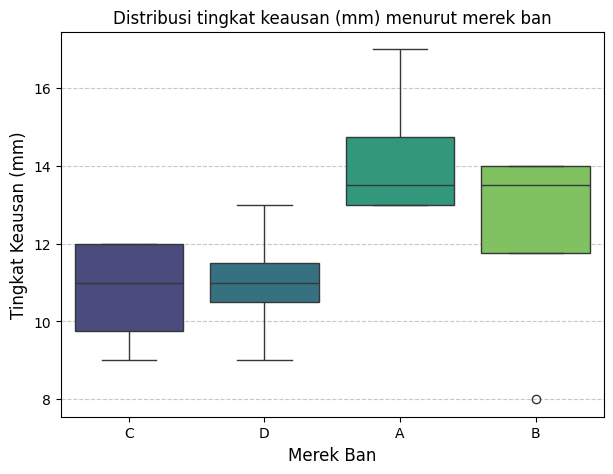

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 5))
sns.boxplot(x='Merek_Ban', y='Tingkat_Keausan', data=df, palette='viridis', hue='Merek_Ban', legend=False)
plt.title('Distribusi tingkat keausan (mm) menurut merek ban')
plt.xlabel('Merek Ban', fontsize=12)
plt.ylabel('Tingkat Keausan (mm)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()